1. Memuat data dan memisahkan Train-Test...

2. Memulai Eksperimen Rasio Undersampling...

Rasio (Minoritas/Mayoritas)    | Precision  | Recall     | F1-Score   | False Positives
-------------------------------------------------------------------------------------
0.06 (Sekitar 1 : 16)          | 0.00       | 0.00       | 0.00       | 0
0.1 (Sekitar 1 : 10)           | 0.50       | 0.02       | 0.04       | 1
0.2 (Sekitar 1 : 5)            | 0.33       | 0.26       | 0.29       | 27
0.3 (Sekitar 1 : 3)            | 0.23       | 0.46       | 0.30       | 79
0.5 (Sekitar 1 : 2)            | 0.19       | 0.74       | 0.30       | 159
0.8 (Sekitar 1 : 1)            | 0.12       | 0.80       | 0.21       | 285
1.0 (50:50 Ekstrem)            | 0.11       | 0.82       | 0.20       | 325

--- KESIMPULAN: Rasio Terbaik Ditemukan di 0.3 (1:3) ---
              precision    recall  f1-score   support

           0       0.97      0.92      0.94       972
           1       0.23      0.46      0.3

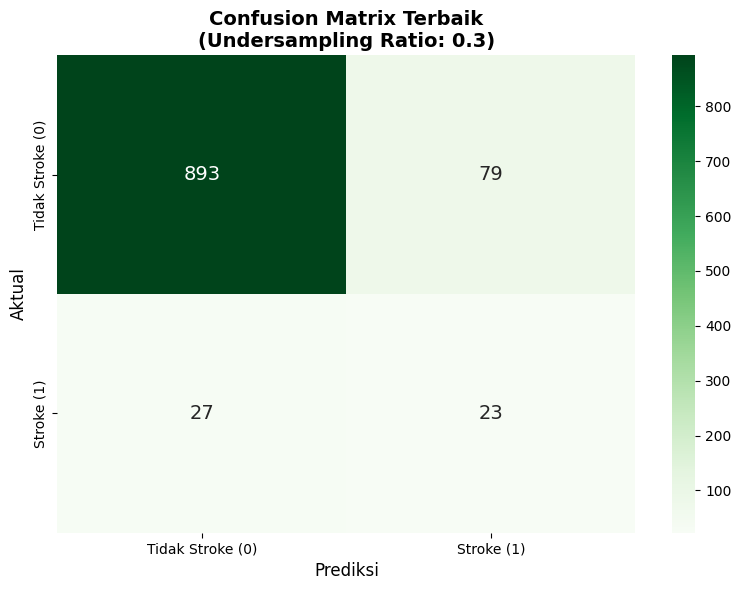

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# TAHAP 1 & 2: PEMUATAN DATA & TRAIN-TEST SPLIT
# =====================================================================
print("1. Memuat data dan memisahkan Train-Test...")
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.drop('id', axis=1, inplace=True)

X = df.drop('stroke', axis=1)
y = df['stroke']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# =====================================================================
# TAHAP 3: PREPROCESSING
# =====================================================================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', ImbPipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', ImbPipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols)
    ])

# =====================================================================
# TAHAP 4: MENCARI RATIO UNDERSAMPLING TERBAIK
# =====================================================================
print("\n2. Memulai Eksperimen Rasio Undersampling...\n")

# Kita tes berbagai rasio: 
# 0.05 (natural/asli), 0.1 (1:10), 0.2 (1:5), 0.3 (1:3), 0.5 (1:2), 1.0 (50:50)
ratios_to_test = [0.06, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0]

print(f"{'Rasio (Minoritas/Mayoritas)':<30} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'False Positives'}")
print("-" * 85)

best_f1 = 0
best_ratio = None
best_model = None
best_y_pred = None

for ratio in ratios_to_test:
    # Membangun pipeline dengan rasio undersampling spesifik
    pipeline_rus = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('undersampler', RandomUnderSampler(sampling_strategy=ratio, random_state=42)),
        ('classifier', XGBClassifier(
            random_state=42, 
            eval_metric='logloss',
            max_depth=3,
            learning_rate=0.05
        ))
    ])
    
    # Melatih model
    pipeline_rus.fit(X_train, y_train)
    
    # Prediksi
    y_pred = pipeline_rus.predict(X_test)
    
    # Kalkulasi Metrik (Hanya untuk kelas 1 / Stroke)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # Menghitung False Positives
    cm = confusion_matrix(y_test, y_pred)
    fp = cm[0][1] if cm.shape == (2,2) else 0
    
    # Mencetak hasil ke layar
    ratio_label = f"{ratio} (Sekitar 1 : {int(1/ratio)})" if ratio != 1.0 else "1.0 (50:50 Ekstrem)"
    print(f"{ratio_label:<30} | {prec:<10.2f} | {rec:<10.2f} | {f1:<10.2f} | {fp}")
    
    # Menyimpan model dengan F1-Score terbaik
    if f1 > best_f1:
        best_f1 = f1
        best_ratio = ratio
        best_model = pipeline_rus
        best_y_pred = y_pred

# =====================================================================
# TAHAP 5: LAPORAN AKHIR & VISUALISASI MODEL TERBAIK
# =====================================================================
ratio_label_best = f"{best_ratio} (1:{int(1/best_ratio)})" if best_ratio != 1.0 else "1.0"
print(f"\n--- KESIMPULAN: Rasio Terbaik Ditemukan di {ratio_label_best} ---")
print(classification_report(y_test, best_y_pred))

# Visualisasi Confusion Matrix Model Terbaik
cm_best = confusion_matrix(y_test, best_y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Tidak Stroke (0)', 'Stroke (1)'], 
            yticklabels=['Tidak Stroke (0)', 'Stroke (1)'],
            annot_kws={"size": 14})
plt.ylabel('Aktual', fontsize=12)
plt.xlabel('Prediksi', fontsize=12)
plt.title(f'Confusion Matrix Terbaik\n(Undersampling Ratio: {best_ratio})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

1. Memuat data dan melakukan Feature Engineering...
2. Melatih model XGBoost...

--- LAPORAN KLASIFIKASI ---
              precision    recall  f1-score   support

           0       0.98      0.90      0.94       972
           1       0.22      0.56      0.32        50

    accuracy                           0.88      1022
   macro avg       0.60      0.73      0.63      1022
weighted avg       0.94      0.88      0.91      1022

ROC-AUC Score: 0.8278

3. Membedah 'Otak' AI menggunakan SHAP...
File gambar 'shap_summary_stroke.png' berhasil disimpan!


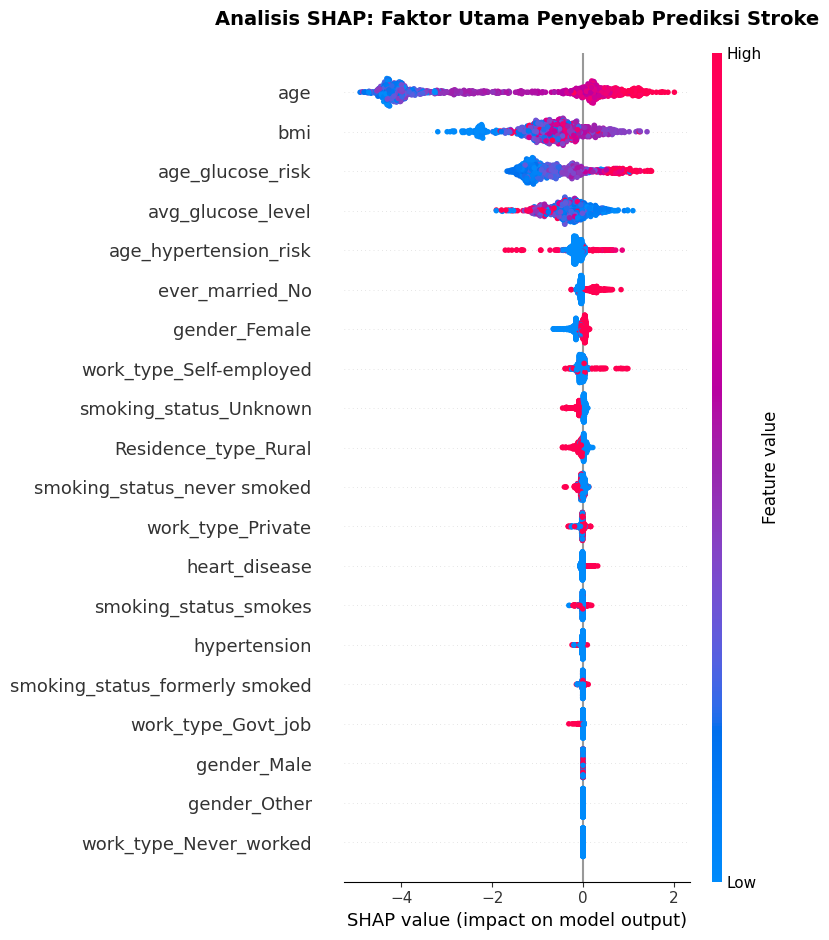

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap  # Library Explainable AI

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# TAHAP 1: PEMUATAN DATA & FEATURE ENGINEERING
# =====================================================================
print("1. Memuat data dan melakukan Feature Engineering...")
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.drop('id', axis=1, inplace=True)

# Membuat fitur interaksi
df['age_glucose_risk'] = df['age'] * df['avg_glucose_level']
df['age_hypertension_risk'] = df['age'] * df['hypertension']

X = df.drop('stroke', axis=1)
y = df['stroke']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# =====================================================================
# TAHAP 2: TRAIN-TEST SPLIT
# =====================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# =====================================================================
# TAHAP 3: PREPROCESSING PIPELINE
# =====================================================================
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# =====================================================================
# TAHAP 4: MEMBANGUN MODEL NATIVE XGBOOST (DENGAN SCALE_POS_WEIGHT)
# =====================================================================
# Menghitung rasio alami untuk penyeimbang otomatis kelas minoritas
ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        random_state=42, 
        eval_metric='logloss',
        scale_pos_weight=ratio, # Senjata rahasia XGBoost
        max_depth=4,            
        learning_rate=0.05,     
        n_estimators=300
    ))
])

# =====================================================================
# TAHAP 5: PELATIHAN & EVALUASI
# =====================================================================
print("2. Melatih model XGBoost...")
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
y_pred_proba = pipeline.predict_proba(X_test)[:, 1]

print("\n--- LAPORAN KLASIFIKASI ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# =====================================================================
# TAHAP 6: EXPLAINABLE AI MENGGUNAKAN SHAP
# =====================================================================
print("\n3. Membedah 'Otak' AI menggunakan SHAP...")

# 1. Transformasi data uji menggunakan preprocessor agar formatnya cocok untuk SHAP
X_test_transformed = preprocessor.transform(X_test)

# 2. Mengambil nama-nama fitur setelah di-OneHotEncode
raw_feature_names = preprocessor.get_feature_names_out()
# Merapikan nama fitur (membuang awalan 'num__' atau 'cat__')
clean_feature_names = [name.split('__')[1] if '__' in name else name for name in raw_feature_names]

# Konversi kembali ke DataFrame agar SHAP bisa membaca nama kolomnya
X_test_df = pd.DataFrame(X_test_transformed, columns=clean_feature_names)

# 3. Ekstrak model XGBoost dari dalam Pipeline
xgb_model = pipeline.named_steps['classifier']

# 4. Inisialisasi TreeExplainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_df)

# =====================================================================
# TAHAP 7: VISUALISASI SHAP SUMMARY PLOT
# =====================================================================
plt.figure(figsize=(10, 8))
# Tampilkan fitur yang paling berpengaruh dari atas ke bawah
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title("Analisis SHAP: Faktor Utama Penyebab Prediksi Stroke", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# Simpan dan tampilkan
plt.savefig("shap_summary_stroke.png", dpi=300, bbox_inches='tight')
print("File gambar 'shap_summary_stroke.png' berhasil disimpan!")
plt.show()

1. Memuat data dan melakukan Feature Engineering...
2. Membuang semua fitur noise secara ekstrem...
Fitur yang tersisa untuk pelatihan: ['age', 'avg_glucose_level', 'bmi', 'age_glucose_risk', 'age_hypertension_risk']

3. Melatih model XGBoost Ultra-Lean...

--- LAPORAN KLASIFIKASI (ULTRA-LEAN) ---
              precision    recall  f1-score   support

           0       0.97      0.87      0.92       972
           1       0.17      0.52      0.26        50

    accuracy                           0.85      1022
   macro avg       0.57      0.69      0.59      1022
weighted avg       0.93      0.85      0.89      1022

ROC-AUC Score: 0.8217


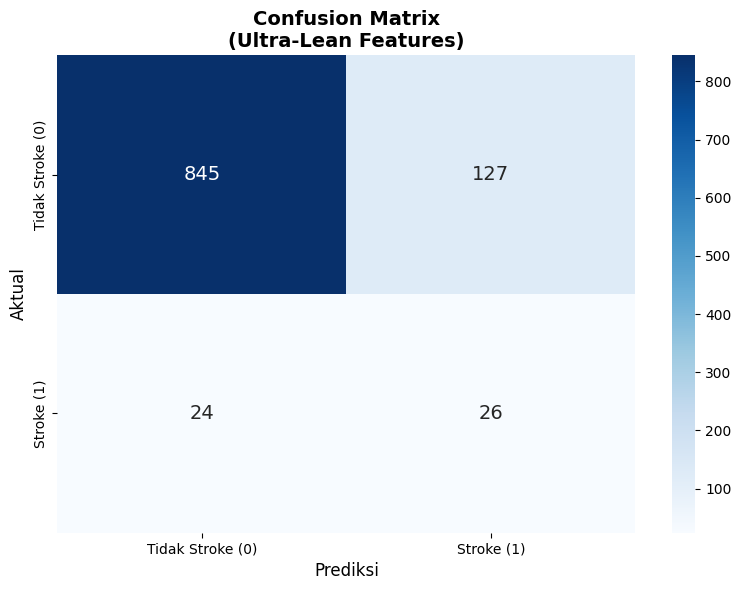


4. Membedah 'Otak' AI menggunakan SHAP...

File gambar berhasil disimpan!


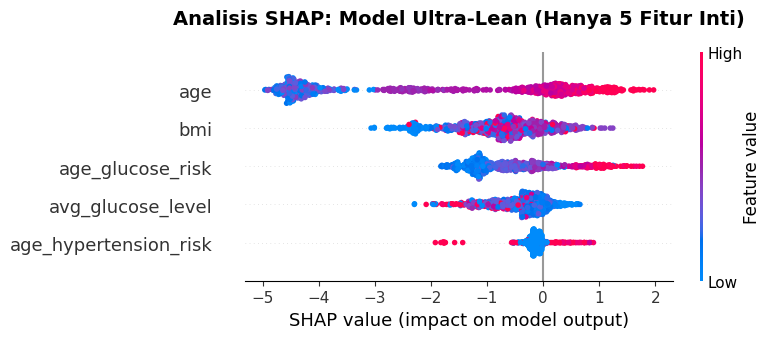

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# TAHAP 1: PEMUATAN DATA & FEATURE ENGINEERING
# =====================================================================
print("1. Memuat data dan melakukan Feature Engineering...")
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# Drop kolom 'id' karena tidak memiliki nilai prediktif
df.drop('id', axis=1, inplace=True)

# Membuat fitur interaksi (Memperkuat sinyal risiko)
df['age_glucose_risk'] = df['age'] * df['avg_glucose_level']
df['age_hypertension_risk'] = df['age'] * df['hypertension']

# =====================================================================
# TAHAP 1.5: FEATURE SELECTION (ULTRA-LEAN MODEL)
# =====================================================================
print("2. Membuang semua fitur noise secara ekstrem...")

# Kita masukkan SEMUA fitur yang terbukti menumpuk di angka 0 pada SHAP
fitur_sampah = [
    'gender', 
    'Residence_type', 
    'ever_married', 
    'work_type',
    'smoking_status', # Terbukti tidak berdampak
    'heart_disease',  # Terbukti tidak berdampak
    'hypertension'    # Dibuang karena perannya digantikan oleh 'age_hypertension_risk'
]

df.drop(fitur_sampah, axis=1, inplace=True)

# Memisahkan Fitur (X) dan Target (y)
X = df.drop('stroke', axis=1)
y = df['stroke']

# Karena semua kolom kategorikal sudah kita buang, X sekarang 100% numerik!
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

print(f"Fitur yang tersisa untuk pelatihan: {list(num_cols)}")

# =====================================================================
# TAHAP 2: TRAIN-TEST SPLIT
# =====================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# =====================================================================
# TAHAP 3: PREPROCESSING PIPELINE (HANYA NUMERIK)
# =====================================================================
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessor sekarang hanya memproses angka
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols)
    ])

# =====================================================================
# TAHAP 4: MEMBANGUN MODEL NATIVE XGBOOST (DENGAN SCALE_POS_WEIGHT)
# =====================================================================
ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        random_state=42, 
        eval_metric='logloss',
        scale_pos_weight=ratio, 
        max_depth=4,            
        learning_rate=0.05,     
        n_estimators=300
    ))
])

# =====================================================================
# TAHAP 5: PELATIHAN & EVALUASI
# =====================================================================
print("\n3. Melatih model XGBoost Ultra-Lean...")
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
y_pred_proba = pipeline.predict_proba(X_test)[:, 1]

print("\n--- LAPORAN KLASIFIKASI (ULTRA-LEAN) ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Tidak Stroke (0)', 'Stroke (1)'], 
            yticklabels=['Tidak Stroke (0)', 'Stroke (1)'],
            annot_kws={"size": 14})
plt.ylabel('Aktual', fontsize=12)
plt.xlabel('Prediksi', fontsize=12)
plt.title('Confusion Matrix\n(Ultra-Lean Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("confusion_matrix_ultralean.png", dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# TAHAP 6: EXPLAINABLE AI MENGGUNAKAN SHAP
# =====================================================================
print("\n4. Membedah 'Otak' AI menggunakan SHAP...")

X_test_transformed = preprocessor.transform(X_test)
raw_feature_names = preprocessor.get_feature_names_out()
clean_feature_names = [name.split('__')[1] if '__' in name else name for name in raw_feature_names]

X_test_df = pd.DataFrame(X_test_transformed, columns=clean_feature_names)
xgb_model = pipeline.named_steps['classifier']

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_df)

# =====================================================================
# TAHAP 7: VISUALISASI SHAP SUMMARY PLOT
# =====================================================================
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title("Analisis SHAP: Model Ultra-Lean (Hanya 5 Fitur Inti)", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("shap_summary_ultralean.png", dpi=300, bbox_inches='tight')
print("\nFile gambar berhasil disimpan!")
plt.show()

1. Memuat data dan menyiapkan fitur inti...
2. Melatih 20 Model XGBoost yang melakukan Voting secara bersamaan...

--- LAPORAN KLASIFIKASI (BALANCED BAGGING ENSEMBLE) ---
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.78      0.23        50

    accuracy                           0.75      1022
   macro avg       0.56      0.76      0.54      1022
weighted avg       0.94      0.75      0.82      1022

ROC-AUC Score: 0.8338


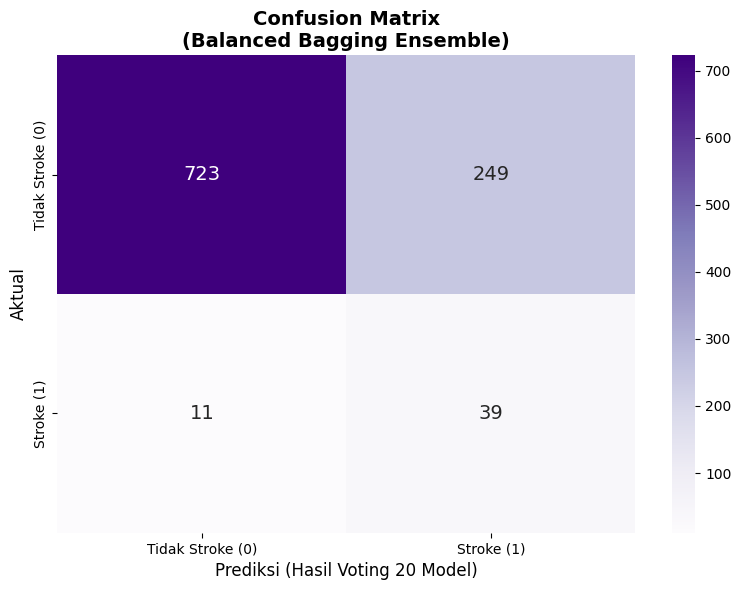

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from imblearn.ensemble import BalancedBaggingClassifier # <--- ALAT PEMECAH DATA SEHAT
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# TAHAP 1: PEMUATAN DATA & PREPARASI ULTRA-LEAN
# =====================================================================
print("1. Memuat data dan menyiapkan fitur inti...")
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.drop('id', axis=1, inplace=True)

df['age_glucose_risk'] = df['age'] * df['avg_glucose_level']
df['age_hypertension_risk'] = df['age'] * df['hypertension']

fitur_sampah = ['gender', 'Residence_type', 'ever_married', 'work_type', 'smoking_status', 'heart_disease', 'hypertension']
df.drop(fitur_sampah, axis=1, inplace=True)

X = df.drop('stroke', axis=1)
y = df['stroke']
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# =====================================================================
# TAHAP 2: TRAIN-TEST SPLIT
# =====================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# =====================================================================
# TAHAP 3: PREPROCESSING PIPELINE
# =====================================================================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols)
    ])

# =====================================================================
# TAHAP 4: MEWUJUDKAN IDE ANDA DENGAN BALANCED BAGGING ENSEMBLE
# =====================================================================
# 1. Kita siapkan "Otak Dasar"-nya (XGBoost)
base_xgb = XGBClassifier(
    random_state=42, 
    eval_metric='logloss',
    max_depth=3,        # Dibuat dangkal agar setiap model spesifik
    learning_rate=0.1
)

# 2. Kita buat Mesin Ensemble yang akan memecah data sehat
# dan membuat banyak model XGBoost
ensemble_model = BalancedBaggingClassifier(
    estimator=base_xgb,
    n_estimators=20,          # Kita suruh AI membuat 20 model XGBoost berbeda!
    sampling_strategy='auto', # Otomatis memecah data sehat agar imbang dengan stroke
    replacement=False,        # Data sehat dibagi rata, tidak duplikat
    random_state=42,
    n_jobs=-1                 # Gunakan seluruh core CPU agar cepat
)

# Gabungkan dengan preprocessor
pipeline_ensemble = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', ensemble_model)
])

# =====================================================================
# TAHAP 5: PELATIHAN & EVALUASI
# =====================================================================
print("2. Melatih 20 Model XGBoost yang melakukan Voting secara bersamaan...")
pipeline_ensemble.fit(X_train, y_train)

y_pred = pipeline_ensemble.predict(X_test)
y_pred_proba = pipeline_ensemble.predict_proba(X_test)[:, 1]

print("\n--- LAPORAN KLASIFIKASI (BALANCED BAGGING ENSEMBLE) ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', 
            xticklabels=['Tidak Stroke (0)', 'Stroke (1)'], 
            yticklabels=['Tidak Stroke (0)', 'Stroke (1)'],
            annot_kws={"size": 14})
plt.ylabel('Aktual', fontsize=12)
plt.xlabel('Prediksi (Hasil Voting 20 Model)', fontsize=12)
plt.title('Confusion Matrix\n(Balanced Bagging Ensemble)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

1. Memuat data dan menyiapkan fitur inti (Ultra-Lean)...

2. Mempersiapkan Data Latih:
   - Total Data Latih Asli : 4088 pasien
   - Data Latih (Hanya Sehat) yang diumpankan ke AI : 3889 pasien
   - Pasien stroke di data latih DIBUANG sepenuhnya untuk fase ini.

3. Memulai Pelatihan Model (Mempelajari Profil Orang Sehat)...
4. Menguji Model pada Data Campuran (Test Set)...

--- LAPORAN KLASIFIKASI (ANOMALY DETECTION) ---
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       972
           1       0.22      0.26      0.24        50

    accuracy                           0.92      1022
   macro avg       0.59      0.61      0.60      1022
weighted avg       0.93      0.92      0.92      1022



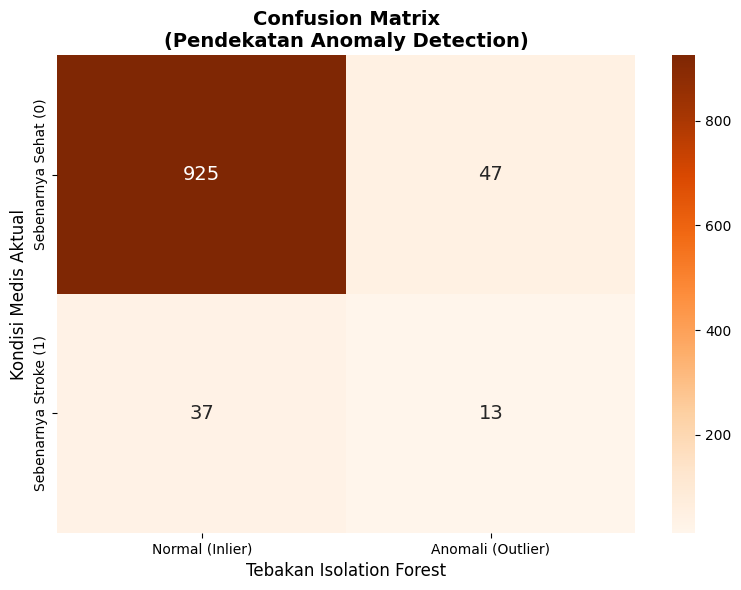

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# TAHAP 1: PEMUATAN DATA & PREPARASI ULTRA-LEAN
# =====================================================================
print("1. Memuat data dan menyiapkan fitur inti (Ultra-Lean)...")
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.drop('id', axis=1, inplace=True)

# Feature Engineering
df['age_glucose_risk'] = df['age'] * df['avg_glucose_level']
df['age_hypertension_risk'] = df['age'] * df['hypertension']

# Membuang fitur yang terbukti menjadi noise di eksperimen sebelumnya
fitur_sampah = ['gender', 'Residence_type', 'ever_married', 'work_type', 'smoking_status', 'heart_disease', 'hypertension']
df.drop(fitur_sampah, axis=1, inplace=True)

X = df.drop('stroke', axis=1)
y = df['stroke']
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# =====================================================================
# TAHAP 2: TRAIN-TEST SPLIT & FILTERING ONE-CLASS (SANGAT PENTING!)
# =====================================================================
# Pisahkan secara normal terlebih dahulu agar distribusi Test Set valid
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# KUNCI UTAMA ANOMALY DETECTION: 
# Kita filter data latih agar HANYA berisi orang sehat (y == 0)
X_train_sehat_saja = X_train[y_train == 0]

print(f"\n2. Mempersiapkan Data Latih:")
print(f"   - Total Data Latih Asli : {len(X_train)} pasien")
print(f"   - Data Latih (Hanya Sehat) yang diumpankan ke AI : {len(X_train_sehat_saja)} pasien")
print(f"   - Pasien stroke di data latih DIBUANG sepenuhnya untuk fase ini.")

# =====================================================================
# TAHAP 3: PREPROCESSING PIPELINE
# =====================================================================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols)
    ])

# =====================================================================
# TAHAP 4: MEMBANGUN MODEL ISOLATION FOREST
# =====================================================================
# Parameter 'contamination' adalah ekspektasi AI terhadap berapa persen 
# dari kumpulan orang "sehat" yang sebenarnya memiliki data melenceng/ekstrem.
# Kita set di angka 0.05 (Asumsi: 5% dari populasi sehat memiliki metrik bahaya)
iso_forest = IsolationForest(
    n_estimators=300,
    contamination=0.05, 
    random_state=42,
    n_jobs=-1
)

pipeline_anomaly = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', iso_forest)
])

# =====================================================================
# TAHAP 5: PELATIHAN (UNSUPERVISED)
# =====================================================================
print("\n3. Memulai Pelatihan Model (Mempelajari Profil Orang Sehat)...")
# Perhatikan: Kita TIDAK memasukkan y_train_sehat karena ini unsupervised
pipeline_anomaly.fit(X_train_sehat_saja)

# =====================================================================
# TAHAP 6: PREDIKSI PADA DATA UJI CAMPURAN (SEHAT & STROKE)
# =====================================================================
print("4. Menguji Model pada Data Campuran (Test Set)...")
# Model Isolation Forest akan memprediksi:
# 1  --> Inlier (Mirip orang sehat)
# -1 --> Outlier (Anomali / Berpotensi Stroke)
prediksi_mentah = pipeline_anomaly.predict(X_test)

# Menerjemahkan output Isolation Forest kembali ke bahasa evaluasi kita:
# Jika 1, ubah jadi 0 (Sehat). Jika -1, ubah jadi 1 (Stroke).
y_pred_final = np.where(prediksi_mentah == 1, 0, 1)

# =====================================================================
# TAHAP 7: EVALUASI & VISUALISASI
# =====================================================================
print("\n--- LAPORAN KLASIFIKASI (ANOMALY DETECTION) ---")
print(classification_report(y_test, y_pred_final))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['Normal (Inlier)', 'Anomali (Outlier)'], 
            yticklabels=['Sebenarnya Sehat (0)', 'Sebenarnya Stroke (1)'],
            annot_kws={"size": 14})
plt.ylabel('Kondisi Medis Aktual', fontsize=12)
plt.xlabel('Tebakan Isolation Forest', fontsize=12)
plt.title('Confusion Matrix\n(Pendekatan Anomaly Detection)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

1. Memuat data dan menyiapkan fitur inti (Ultra-Lean)...
2. Membangun Arsitektur Stacking Ensemble Lapis Ganda...
3. Melatih model Stacking (Proses ini melatih 3 algoritma sekaligus + 1 meta-model)...

--- LAPORAN KLASIFIKASI (STACKING ENSEMBLE) ---
              precision    recall  f1-score   support

           0       0.99      0.75      0.85       972
           1       0.14      0.78      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022

ROC-AUC Score: 0.8283

File gambar 'confusion_matrix_stacking.png' berhasil disimpan!


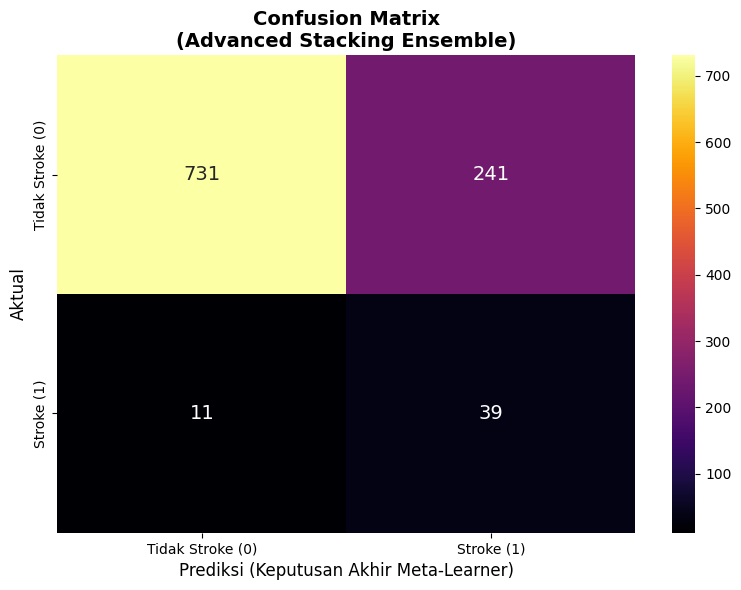

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn & Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Algoritma Machine Learning Lapis Pertama (The Big Three)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Algoritma Lapis Kedua (Meta-Learner) & Stacking
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier

import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# TAHAP 1: PEMUATAN DATA & PREPARASI ULTRA-LEAN
# =====================================================================
print("1. Memuat data dan menyiapkan fitur inti (Ultra-Lean)...")
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.drop('id', axis=1, inplace=True)

# Feature Engineering
df['age_glucose_risk'] = df['age'] * df['avg_glucose_level']
df['age_hypertension_risk'] = df['age'] * df['hypertension']

# Feature Selection (Membuang noise ekstrem)
fitur_sampah = ['gender', 'Residence_type', 'ever_married', 'work_type', 'smoking_status', 'heart_disease', 'hypertension']
df.drop(fitur_sampah, axis=1, inplace=True)

X = df.drop('stroke', axis=1)
y = df['stroke']
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# =====================================================================
# TAHAP 2: TRAIN-TEST SPLIT
# =====================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Menghitung rasio imbalance untuk penyeimbang otomatis
ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)

# =====================================================================
# TAHAP 3: PREPROCESSING PIPELINE
# =====================================================================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols)
    ])

# =====================================================================
# TAHAP 4: MERAKIT ARSITEKTUR STACKING ENSEMBLE
# =====================================================================
print("2. Membangun Arsitektur Stacking Ensemble Lapis Ganda...")

# Lapis 1 (Base Learners): Tiga mesin Gradient Boosting dengan karakteristik berbeda
# 1. XGBoost: Cenderung agresif dan detail
xgb = XGBClassifier(
    random_state=42, 
    eval_metric='logloss',
    scale_pos_weight=ratio, 
    max_depth=4,
    n_jobs=-1
)

# 2. LightGBM: Sangat cepat dan fokus pada akurasi daun pohon (leaf-wise)
lgbm = LGBMClassifier(
    random_state=42,
    class_weight='balanced', # Penanganan imbalance native
    max_depth=4,
    n_jobs=-1,
    verbose=-1
)

# 3. CatBoost: Raja dari robustness, stabil dan tahan terhadap overfitting
cat = CatBoostClassifier(
    random_state=42,
    auto_class_weights='Balanced', # Penanganan imbalance native
    depth=4,
    verbose=0, # Mematikan log agar terminal bersih
    thread_count=-1
)

# Kumpulkan ketiganya sebagai estimator dasar
base_estimators = [
    ('xgb', xgb),
    ('lgbm', lgbm),
    ('cat', cat)
]

# Lapis 2 (Meta-Learner): Logistic Regression
# Ia akan membaca probabilitas tebakan dari XGB, LGBM, dan CatBoost,
# lalu belajar algoritma mana yang paling jujur/akurat untuk pasien tertentu.
meta_learner = LogisticRegression(class_weight='balanced')

# Bungkus semuanya ke dalam Stacking Classifier
stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=5, # Menggunakan Cross-Validation 5-fold untuk melatih meta-learner secara objektif
    passthrough=False, # Meta-learner HANYA melihat prediksi lapis 1, bukan fitur mentahnya
    n_jobs=-1
)

# Satukan dengan preprocessor
pipeline_stacking = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('stacking', stacking_clf)
])

# =====================================================================
# TAHAP 5: PELATIHAN & EVALUASI
# =====================================================================
print("3. Melatih model Stacking (Proses ini melatih 3 algoritma sekaligus + 1 meta-model)...")
pipeline_stacking.fit(X_train, y_train)

# Prediksi
y_pred = pipeline_stacking.predict(X_test)
y_pred_proba = pipeline_stacking.predict_proba(X_test)[:, 1]

# =====================================================================
# TAHAP 6: LAPORAN & VISUALISASI
# =====================================================================
print("\n--- LAPORAN KLASIFIKASI (STACKING ENSEMBLE) ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='inferno', 
            xticklabels=['Tidak Stroke (0)', 'Stroke (1)'], 
            yticklabels=['Tidak Stroke (0)', 'Stroke (1)'],
            annot_kws={"size": 14})
plt.ylabel('Aktual', fontsize=12)
plt.xlabel('Prediksi (Keputusan Akhir Meta-Learner)', fontsize=12)
plt.title('Confusion Matrix\n(Advanced Stacking Ensemble)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("confusion_matrix_stacking.png", dpi=300, bbox_inches='tight')
print("\nFile gambar 'confusion_matrix_stacking.png' berhasil disimpan!")
plt.show()